# NVIDIA vs AI baskets: hedge ratios

**Goal.** Estimate how much of an AI basket (single stocks or ETFs) to short against a
long NVDA position, and build the borrow- and financing-adjusted total return of that
hedged position.

**This notebook, step 1: data sanity checks only.** Hedge ratios (step 2), the total
return series (step 3) and the basket comparison (step 4) will be added below.

Data (pulled by `make data`, saved under `data/raw/`):

| Source | What | Coverage |
|---|---|---|
| CRSP (`crsp.dsf` to 2024, `crsp.dsf_v2` for 2025) | daily total and price returns | 2019 to 2025-12-31 |
| yfinance | adjusted close (total return), close, dividends | 2019 to today; fills 2026 |
| Markit Securities Finance | daily indicative borrow fee and rebate, DCBS, utilisation | 2019 to mid-Nov 2026 |
| ETF Global | ETF constituents: daily NVDA weight, month-end full holdings | 2019 to 2026-10-30 |
| OptionMetrics `borrate` | put-call-parity implied borrow rate | 2019 to 2025-08-29 |
| 3m T-bill (FRED DTB3 or ^IRX); French RF as fallback | daily risk-free rate | 2019 to today |

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nvai.config import FIGURES, settings
from nvai.data import load

FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160, "display.max_columns", 30)

S = settings()
U = S["universe"]
TARGET, ETFS, STOCKS = U["target"], U["etfs"], U["stocks"]

# Chart styling: recessive axes and grid, thin lines, one fixed color per entity.
# Categorical palette (validated colorblind-safe order). NVDA always gets near-black.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6",
           "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "lines.linewidth": 1.6, "legend.frameon": False, "font.size": 9,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
COLOR = {TARGET: INK, "SPY": INK2} | dict(zip(ETFS, PALETTE))


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")
    plt.show()

## 1. Load everything

`load.returns()` is CRSP where CRSP has a value and yfinance otherwise. CRSP stops at
2025-12-31, so every 2026 return is from yfinance. VRT's returns before its
2020-02-07 listing (the GS Acquisition SPAC) are masked.

In [2]:
ret = load.returns()               # total returns, dates x tickers
src = load.return_source()         # which source each value came from
rf = load.risk_free()              # daily decimal
fee = load.borrow_fees()           # Markit indicative fee, annualized decimal
fee_om = load.optionm_borrow(30)   # OptionMetrics ~30-day implied borrow
nvw = load.nvda_weight()           # NVDA weight in each ETF
hold = load.etf_holdings()         # month-end ETF holdings

print(f"returns {ret.shape}, {ret.index.min().date()} to {ret.index.max().date()}")

returns (1984, 27), 2019-01-02 to 2026-11-20


## 2. Coverage by ticker

One row per ticker: first and last return, how many days come from each source,
and Markit / OptionMetrics coverage. Gaps to know about:
- **ARM** trades only from its 2023-09-14 IPO.
- **VRT** starts at the 2020-02-07 listing.
- **OptionMetrics** ends 2025-08-29; Markit is the borrow source after that.

In [3]:
cov = pd.DataFrame({
    "first": ret.apply(pd.Series.first_valid_index).dt.date,
    "last": ret.apply(pd.Series.last_valid_index).dt.date,
    "n_crsp": (src == "crsp").sum(),
    "n_yf": (src == "yf").sum(),
    "markit_first": fee.apply(pd.Series.first_valid_index).dt.date,
    "markit_last": fee.apply(pd.Series.last_valid_index).dt.date,
    "markit_days": fee.notna().sum(),
    "optionm_days": fee_om.notna().sum(),
}).reindex([TARGET, "SPY", *ETFS, *STOCKS])
cov["group"] = ["target", "market"] + ["etf"] * len(ETFS) + ["stock"] * len(STOCKS)
cov

,first,last,n_crsp,n_yf,markit_first,markit_last,markit_days,optionm_days,group
ticker,,,,,,,,,
NVDA,2019-01-02,2026-11-20,1760,224,2019-01-01,2026-11-13,2052,1160,target
SPY,2019-01-02,2026-11-20,1760,224,2019-01-01,2026-11-13,2052,1174,market
QQQ,2019-01-02,2026-11-20,1760,224,2019-01-01,2026-11-13,2052,1358,etf
SMH,2019-01-02,2026-11-20,1760,224,2019-01-01,2026-11-13,2052,1546,etf
SOXX,2019-01-02,2026-11-20,1760,224,2019-01-01,2026-11-13,2052,1580,etf
XLK,2019-01-02,2026-11-20,1760,224,2019-01-01,2026-11-13,2052,1410,etf
IGV,2019-01-02,2026-11-20,1760,224,2019-01-01,2026-11-13,2052,1624,etf
BOTZ,2019-01-02,2026-11-20,1760,224,2019-01-01,2026-11-13,2052,1535,etf
AIQ,2019-01-02,2026-11-20,1760,224,2019-01-03,2026-11-13,1900,918,etf


## 3. CRSP vs yfinance

Both are total returns, so on the overlap (2019 to 2025) they should agree almost
exactly. Small differences come from dividend reinvestment timing and the closing
price used. A low correlation would mean a wrong ticker-to-permno mapping.

Two known differences, both handled by preferring CRSP:
- **SMCI** traded OTC from Aug 2019 to Jan 2020 (late filings). CRSP has no returns
  then (261 missing days), so `load.returns()` fills those days from yfinance. The
  cumulative return below treats CRSP's missing days as zero, which is why it is lower.
- **DELL** on 2021-11-02: CRSP counts the VMware spin-off as a distribution (+2.3%);
  yfinance's adjusted close does not (-3.4%).

In [4]:
crsp, yf = load.crsp_returns(), load.yf_returns()
common = crsp.columns.intersection(yf.columns)
both = crsp[common].join(yf[common], lsuffix="_c", rsuffix="_y", how="inner")
cmp = pd.DataFrame({
    t: {"corr": both[f"{t}_c"].corr(both[f"{t}_y"]),
        "mean_abs_diff_bp": 1e4 * (both[f"{t}_c"] - both[f"{t}_y"]).abs().mean(),
        "cum_ret_crsp": (1 + both[f"{t}_c"].fillna(0)).prod() - 1,
        "cum_ret_yf": (1 + both[f"{t}_y"].fillna(0)).prod() - 1}
    for t in common}).T.sort_values("corr")
cmp.round(4)

,corr,mean_abs_diff_bp,cum_ret_crsp,cum_ret_yf
DELL,0.9988,0.3430,5.0825,4.7496
SMCI,0.9999,0.2299,9.8407,18.3841
VRT,0.9999,0.3358,15.6963,15.6973
QQQ,1.0000,0.0129,3.1498,3.1444
SOXX,1.0000,0.0163,5.1235,5.1224
MRVL,1.0000,0.0471,4.3416,4.3425
SPY,1.0000,0.0104,2.0325,2.0308
INTC,1.0000,0.0269,-0.0894,-0.0893
AMZN,1.0000,0.0092,1.9993,1.9994
QCOM,1.0000,0.0233,2.5256,2.5296


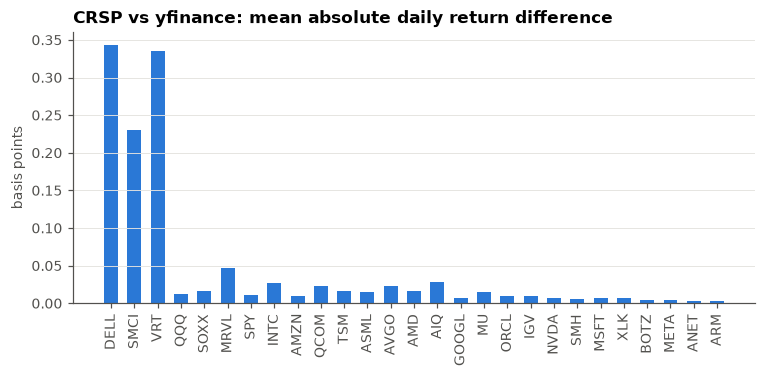

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(cmp.index, cmp["mean_abs_diff_bp"], color=PALETTE[0], width=0.6)
ax.set_title("CRSP vs yfinance: mean absolute daily return difference")
ax.set_ylabel("basis points")
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="x", visible=False)
save(fig, "crsp_vs_yf_diff")

## 4. Cumulative total return: NVDA vs the ETFs

Log scale, $1 invested on the first common date. NVDA's run dominates everything
else, which is the reason a hedge ratio well above 1 per dollar of ETF is likely.

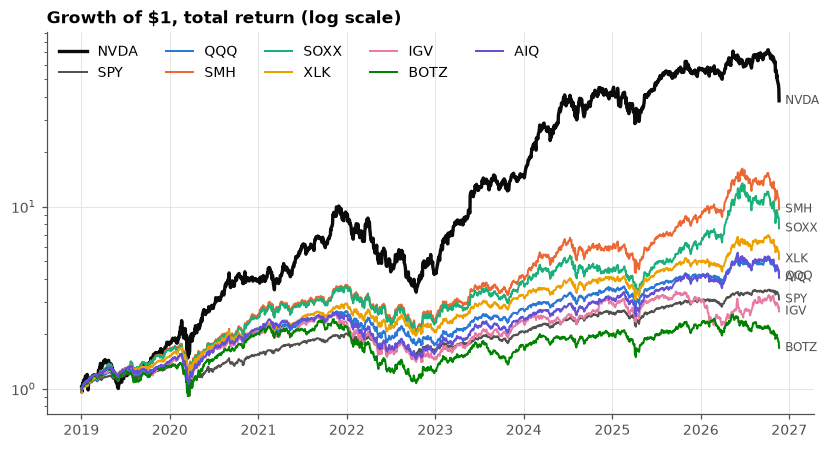

In [6]:
cols = [TARGET, "SPY", *ETFS]
r = ret[cols].dropna(how="all")
wealth = (1 + r.fillna(0)).cumprod()
fig, ax = plt.subplots(figsize=(9, 4.5))
for t in cols:
    ax.plot(wealth.index, wealth[t], color=COLOR[t], lw=2.2 if t == TARGET else 1.3,
            label=t)
    ax.annotate(t, (wealth.index[-1], wealth[t].iat[-1]), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK2)
ax.set_yscale("log")
ax.set_title("Growth of $1, total return (log scale)")
ax.legend(ncol=5, loc="upper left")
save(fig, "cum_return_nvda_vs_etfs")

## 5. NVDA's weight inside each ETF

A short ETF position is partly a short NVDA position. With NVDA weight `w` in the ETF,
shorting `h` dollars of the ETF takes `h * w` dollars of NVDA exposure off, which caps
how cleanly an ETF can isolate "AI ex NVDA". IGV (software) holds no NVDA.

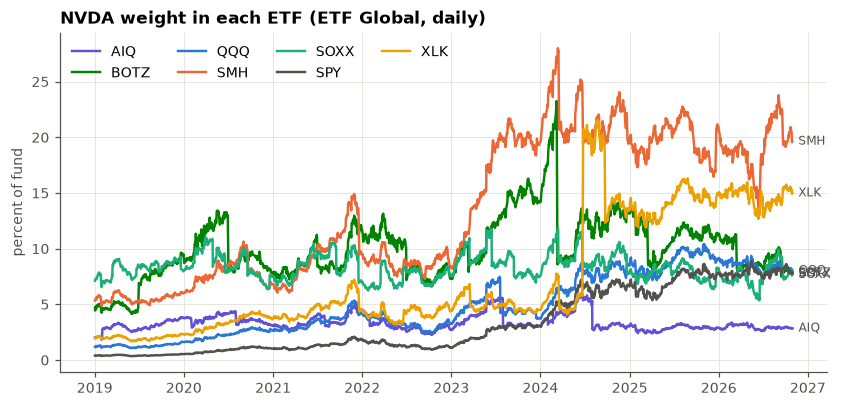

,"NVDA weight, % (latest)"
composite_ticker,
AIQ,2.85
BOTZ,7.8
QQQ,8.01
SMH,19.62
SOXX,7.65
SPY,7.77
XLK,14.98


In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
for e in nvw.columns:
    s = nvw[e].dropna()
    ax.plot(s.index, 100 * s, color=COLOR.get(e, INK2), label=e)
    ax.annotate(e, (s.index[-1], 100 * s.iat[-1]), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK2)
ax.set_title("NVDA weight in each ETF (ETF Global, daily)")
ax.set_ylabel("percent of fund")
ax.legend(ncol=4, loc="upper left")
save(fig, "nvda_weight_in_etfs")

latest_w = nvw.ffill().iloc[-1].mul(100).round(2).rename("NVDA weight, % (latest)")
latest_w.to_frame()

Top 10 holdings of each ETF at the latest month end, for reference.

In [8]:
last = hold[hold.as_of_date == hold.groupby("composite_ticker").as_of_date.transform("max")]
top = (last.sort_values("weight", ascending=False).groupby("composite_ticker").head(10)
           .assign(weight=lambda d: (100 * d.weight).round(1)))
top.pivot_table(index=top.groupby("composite_ticker").cumcount() + 1,
                columns="composite_ticker", values="constituent_ticker", aggfunc="first")

composite_ticker,AIQ,BOTZ,IGV,QQQ,SMH,SOXX,SPY,XLK
1,PLTR,ISRG,PLTR,AAPL,NVDA,AMD,NVDA,NVDA
2,MSFT,6861,PANW,NVDA,TSM,INTC,AAPL,AAPL
3,TSLA,6954,MSFT,MSFT,AMD,MU,MSFT,MSFT
4,SPCX,NVDA,CRWD,MU,AVGO,NVDA,AMZN,AMD
5,ORCL,ABBN,ORCL,AMZN,TXN,AVGO,GOOGL,AVGO
6,AAPL,6273,CRM,AMD,ADI,TXN,AVGO,MU
7,AMZN,6383,NOW,TSLA,MU,ADI,META,INTC
8,META,300124,ADBE,META,ASML,QCOM,GOOG,PLTR
9,NVDA,CGNX,CDNS,WMT,KLAC,MRVL,TSLA,CSCO
10,TSM,TSLA,SNPS,GOOGL,SKHYV,KLAC,LLY,AMAT


## 6. Borrow costs

Markit's indicative fee is the annualized cost to borrow a share, as a decimal
(0.003 = 30 bp a year). Large, liquid names sit at general-collateral levels of about
25-40 bp; hard-to-borrow names are higher. These fees go into the total return series
in step 3 as the cost of the short leg.

Small multiples: one panel per name, on a common 0-150 bp scale so levels compare.
A few short spikes go off the top (e.g. ARM right after its IPO, SMCI around its 2020
relisting); each panel's title gives the median and the max.

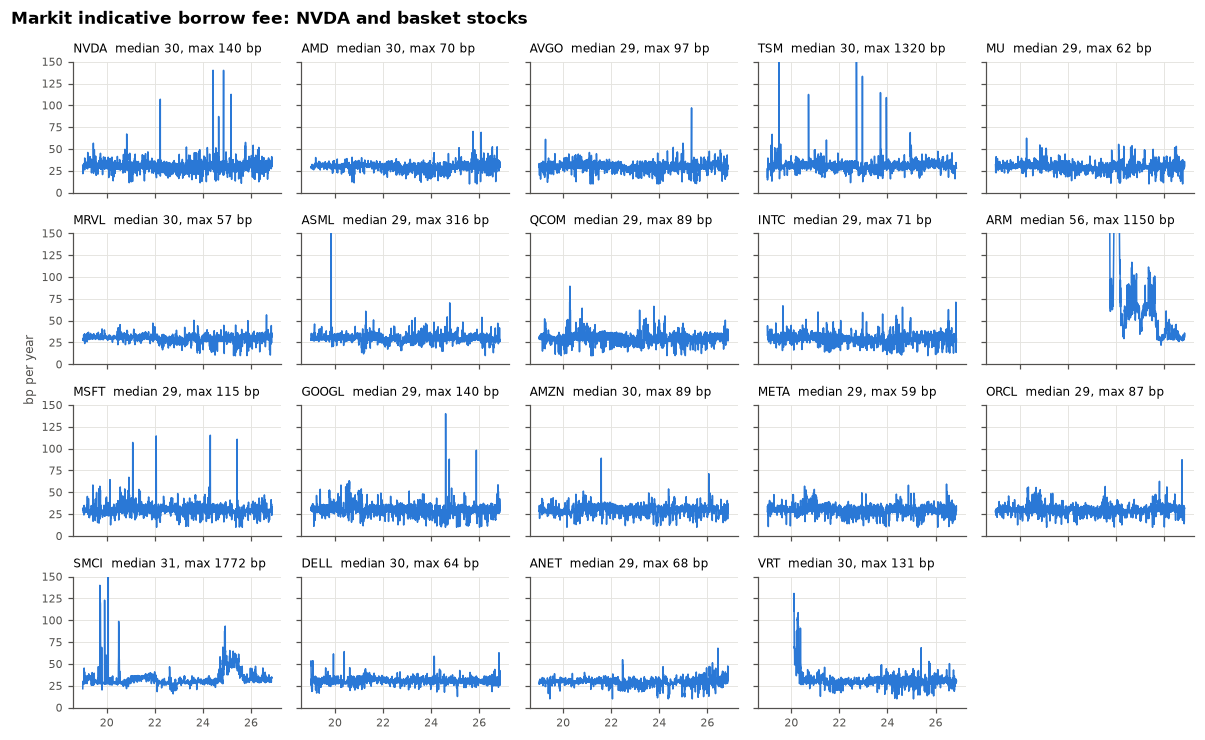

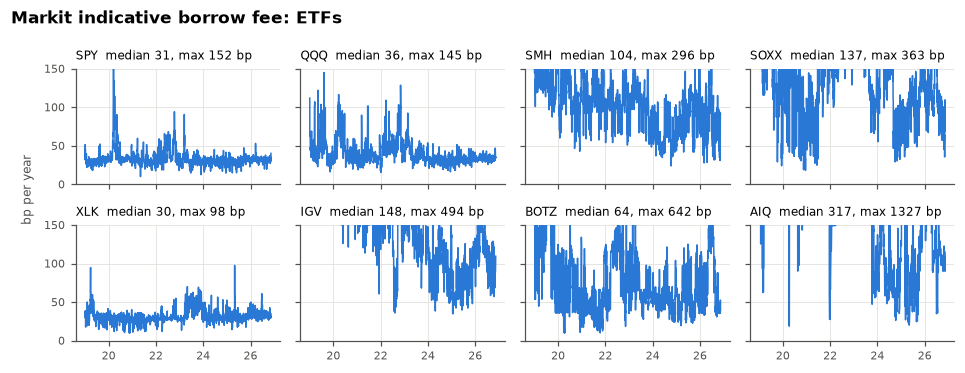

In [9]:
def fee_panels(names, title, fname, ncols=5):
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.2 * ncols, 1.7 * nrows),
                             sharex=True, sharey=True)
    for ax, t in zip(axes.flat, names):
        s = 1e4 * fee[t].dropna()
        ax.plot(s.index, s, color=PALETTE[0], lw=1)
        ax.set_title(f"{t}  median {s.median():.0f}, max {s.max():.0f} bp", fontsize=8,
                     fontweight="normal")
        ax.set_ylim(0, 150)
        ax.xaxis.set_major_locator(mdates.YearLocator(2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%y"))
        ax.tick_params(labelsize=7)
    for ax in axes.flat[len(names):]:
        ax.set_visible(False)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.supylabel("bp per year", fontsize=8, color=INK2)
    fig.tight_layout()
    save(fig, fname)


fee_panels([TARGET, *STOCKS], "Markit indicative borrow fee: NVDA and basket stocks",
           "borrow_fee_stocks")
fee_panels(["SPY", *ETFS], "Markit indicative borrow fee: ETFs", "borrow_fee_etfs", ncols=4)

**Cross-check: Markit vs OptionMetrics for NVDA.** OptionMetrics backs out a borrow
rate from put-call parity at each expiry (here the one closest to 30 days). It is
much noisier and can go negative, but it should track Markit on average.

Note the ETF panels above: shorting niche ETFs is expensive. SMH, SOXX, IGV and
especially AIQ carry fees of 1-3% a year versus about 30 bp for QQQ, XLK and the large
single names. That cost drag will matter when comparing hedges.

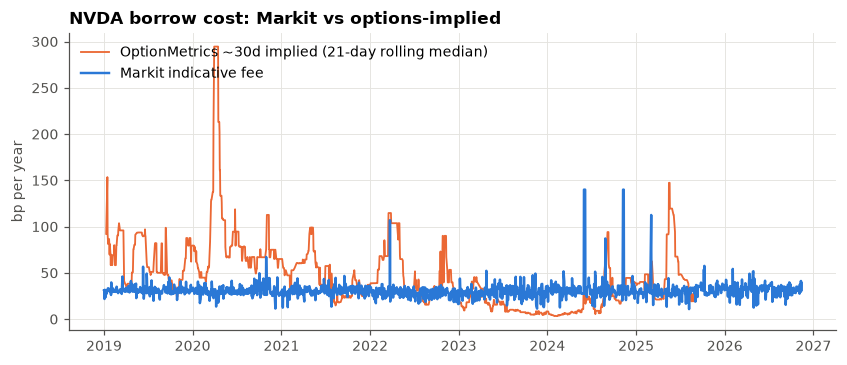

In [10]:
nv = pd.concat({"Markit fee": fee[TARGET], "OptionMetrics ~30d": fee_om[TARGET]},
               axis=1).dropna(how="all")
fig, ax = plt.subplots(figsize=(9, 3.5))
om = nv["OptionMetrics ~30d"].dropna()
ax.plot(om.index, 1e4 * om.rolling(21, min_periods=5).median(), color=PALETTE[1],
        lw=1.2, label="OptionMetrics ~30d implied (21-day rolling median)")
ax.plot(nv.index, 1e4 * nv["Markit fee"], color=PALETTE[0], label="Markit indicative fee")
ax.set_title("NVDA borrow cost: Markit vs options-implied")
ax.set_ylabel("bp per year")
ax.legend(loc="upper left")
save(fig, "nvda_borrow_markit_vs_optionm")

**Cash-rate check.** Markit's rebate is what a short seller earns on the cash
collateral, so fee + rebate should be close to the overnight rate. That is a
check on the fee units and on our risk-free series.

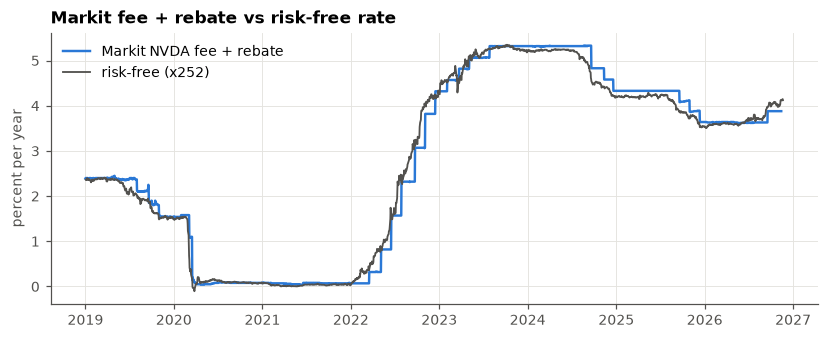

In [11]:
raw = load.markit_raw()
nvr = (raw[(raw.ticker == TARGET) & raw.indicativefee.notna()]
          .sort_values("lendablevalue").drop_duplicates("datadate", keep="last")
          .set_index("datadate").sort_index())
implied_cash = (nvr.indicativefee + nvr.indicativerebate).rename("fee + rebate")
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(implied_cash.index, 100 * implied_cash, color=PALETTE[0],
        label="Markit NVDA fee + rebate")
ax.plot(rf.index, 100 * 252 * rf, color=INK2, lw=1.2, label="risk-free (x252)")
ax.set_title("Markit fee + rebate vs risk-free rate")
ax.set_ylabel("percent per year")
ax.legend(loc="upper left")
save(fig, "markit_cash_rate_check")

## 7. Headline numbers

In [12]:
recent = fee.loc[fee.index >= fee.index.max() - pd.DateOffset(years=1)]
headline = {
    "NVDA weight in QQQ (latest, %)": latest_w.get("QQQ"),
    "NVDA weight in SMH (latest, %)": latest_w.get("SMH"),
    "NVDA weight in XLK (latest, %)": latest_w.get("XLK"),
    "NVDA Markit fee, full-sample mean (bp)": 1e4 * fee[TARGET].mean(),
    "NVDA Markit fee, last 12m mean (bp)": 1e4 * recent[TARGET].mean(),
    "Basket stocks, last 12m median fee (bp)": 1e4 * recent[STOCKS].median().median(),
    "Highest last-12m mean fee": f"{recent[STOCKS + ETFS].mean().idxmax()} "
                                 f"({1e4 * recent[STOCKS + ETFS].mean().max():.0f} bp)",
    "NVDA total return since 2019 (x)": wealth[TARGET].iat[-1],
    "Risk-free, latest (% p.a.)": 100 * 252 * rf.iat[-1],
}
pd.Series(headline, name="value").to_frame()

,value
"NVDA weight in QQQ (latest, %)",8.01
"NVDA weight in SMH (latest, %)",19.62
"NVDA weight in XLK (latest, %)",14.98
"NVDA Markit fee, full-sample mean (bp)",30.752266
"NVDA Markit fee, last 12m mean (bp)",32.077004
"Basket stocks, last 12m median fee (bp)",30.36455
Highest last-12m mean fee,AIQ (148 bp)
NVDA total return since 2019 (x),38.015703
"Risk-free, latest (% p.a.)",4.122


## Next steps (to be added here)

2. **Hedge ratios.** OLS beta of NVDA on each basket (equal and cap weighted), full
   sample and rolling; minimum-variance multi-name hedge; out-of-sample residual vol.
3. **Total return series.** Long NVDA, short `h` x basket: short leg pays the Markit
   fee (default 25 bp where missing) and earns the rebate; long leg financed at rf plus
   a spread.
4. **Comparison.** Tracking error, drawdowns and cost drag across baskets and ETFs.